# 02 · Data preprocessing and feature engineering
Builds the reproducible preprocessing pipeline (`src/preprocessing.py`), demonstrates that no information leaks from validation/test data, checks multicollinearity, and chooses a feature set using **training cross-validation and validation data only**. The test set is not touched in this notebook.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from src.data_loader import load_raw, TARGET
from src.preprocessing import (clean_categories, add_features, split_data, build_preprocessor,
                               feature_columns, ENGINEERED, SEED, _signed_log)
from src import visualisation as viz
viz.set_style()
RESULTS = "../results"
raw = load_raw()

## 1. Stateless cleaning and feature engineering
Two row-wise steps that learn nothing from other rows, so applying them before the split cannot leak:
- merge undocumented codes (EDUCATION 0, 5, 6 → 4 "others"; MARRIAGE 0 → 3 "others");
- add candidate features: September and 6-month-average **credit utilisation** (bill ÷ limit, capped at 2), average **repayment ratio** (paid ÷ billed, capped at 1), **worst delay**, **number of late months**, and a centred **age²** term (age − 35)² for the U-shaped age effect seen in EDA.

EDUCATION: {1: 10585, 2: 14030, 3: 4917, 4: 468}
MARRIAGE: {1: 13659, 2: 15964, 3: 377}


,count,mean,std,min,25%,50%,75%,max
util_sep,30000.0,0.42,0.40,-0.62,0.02,0.31,0.83,2.0
util_avg,30000.0,0.37,0.35,-0.23,0.03,0.28,0.69,2.0
pay_ratio_avg,30000.0,0.35,0.38,0.00,0.04,0.11,0.71,1.0
max_delay,30000.0,0.68,1.07,0.00,0.00,0.00,2.00,8.0
n_late_months,30000.0,0.83,1.55,0.00,0.00,0.00,1.00,6.0
age_sq,30000.0,85.20,126.30,0.00,9.00,49.00,100.00,1936.0


'results/figures/10_engineered_features_vs_default.png'

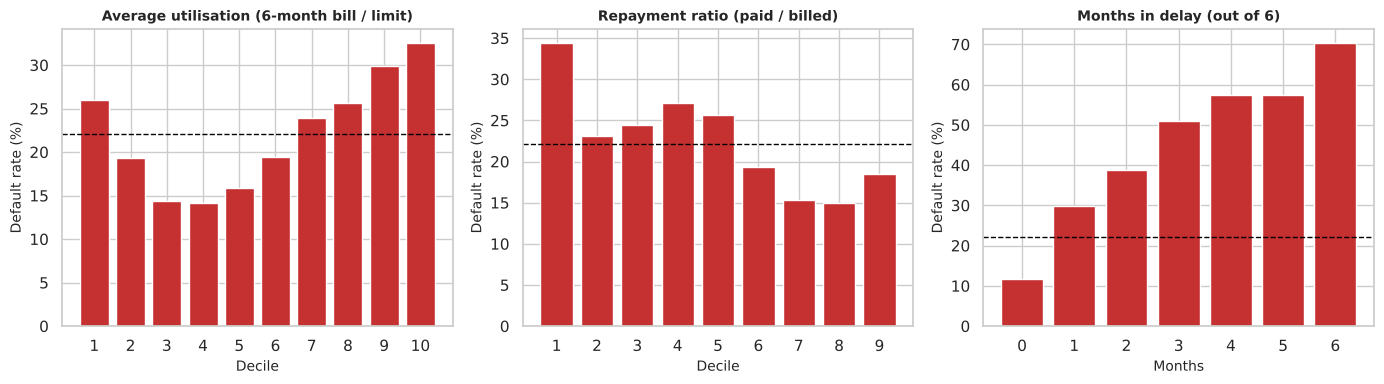

In [2]:
df = add_features(clean_categories(raw))
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE:", df["MARRIAGE"].value_counts().sort_index().to_dict())
display(df[ENGINEERED].describe().round(2).T)
viz.plot_engineered_vs_default(df)

Only the number of late months is monotone in default risk (11.7% with none, rising to 70.3% with all six late). Repayment ratio is broadly decreasing (default about 34% in the lowest decile, 15% around the 7th and 8th) but not strictly. Average utilisation is **U-shaped**: the lowest decile defaults at 26%, the 3rd–4th deciles at about 14%, and the top decile at 32.5%. A linear term cannot capture that, so utilisation is an imperfect feature; a banded version is a candidate for later work. Whether they actually improve the model is tested in section 5, not assumed.

## 2. Train / validation / test split
Stratified 60/20/20 split with seed 42. Row order is not documented as chronological and all data comes from one window, so a time-based split is not possible (see limitations in `docs/methodology.md`).

In [3]:
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(df)
summary = pd.DataFrame({"rows": [len(X_tr), len(X_va), len(X_te)],
                        "defaults": [int(y_tr.sum()), int(y_va.sum()), int(y_te.sum())],
                        "default_rate": [y_tr.mean(), y_va.mean(), y_te.mean()]},
                       index=["train", "validation", "test"]).round(4)
display(summary)
assert not (set(X_tr.index) & set(X_va.index)) and not (set(X_tr.index) & set(X_te.index)) and not (set(X_va.index) & set(X_te.index))
print("splits are disjoint; total rows =", len(X_tr) + len(X_va) + len(X_te))

,rows,defaults,default_rate
train,18000,3982,0.2212
validation,6000,1327,0.2212
test,6000,1327,0.2212


splits are disjoint; total rows = 30000


## 3. Pipeline and leakage check
`build_preprocessor` is a `ColumnTransformer`: amounts get a signed-log transform then scaling, numeric/ordinal columns are scaled, EDUCATION and MARRIAGE are one-hot encoded. The check below confirms the scaler learned its mean from the **training rows only**.

In [4]:
prep = build_preprocessor("engineered").fit(X_tr)
scaler = prep.named_transformers_["log_amounts"].named_steps["scale"]
col = "LIMIT_BAL"; i = feature_columns("engineered")[0].index(col)
train_mean = _signed_log(X_tr[col]).mean(); all_mean = _signed_log(df[col]).mean()
print(f"fitted scaler mean for {col}: {scaler.mean_[i]:.6f}")
print(f"mean of train rows:          {train_mean:.6f}")
print(f"mean of all rows:            {all_mean:.6f}")
assert np.isclose(scaler.mean_[i], train_mean) and not np.isclose(scaler.mean_[i], all_mean)
Z_tr, Z_va = prep.transform(X_tr), prep.transform(X_va)
print("train transformed shape:", Z_tr.shape, "| validation:", Z_va.shape, "| any NaN:", bool(Z_tr.isna().any().any() or Z_va.isna().any().any()))
print("validation standardised LIMIT_BAL mean (not exactly 0, as expected):", round(Z_va[col].mean(), 4))

fitted scaler mean for LIMIT_BAL: 11.665284
mean of train rows:          11.665284
mean of all rows:            11.663016
train transformed shape: (18000, 31) | validation: (6000, 31) | any NaN: False
validation standardised LIMIT_BAL mean (not exactly 0, as expected): -0.0177


The fitted mean matches the training rows and differs from the all-rows mean, so validation and test data do not influence the transformation. Inside cross-validation the same guarantee holds because the preprocessor is part of the `Pipeline` and is refitted on each training fold.

'results/figures/09_amount_transform_effect.png'

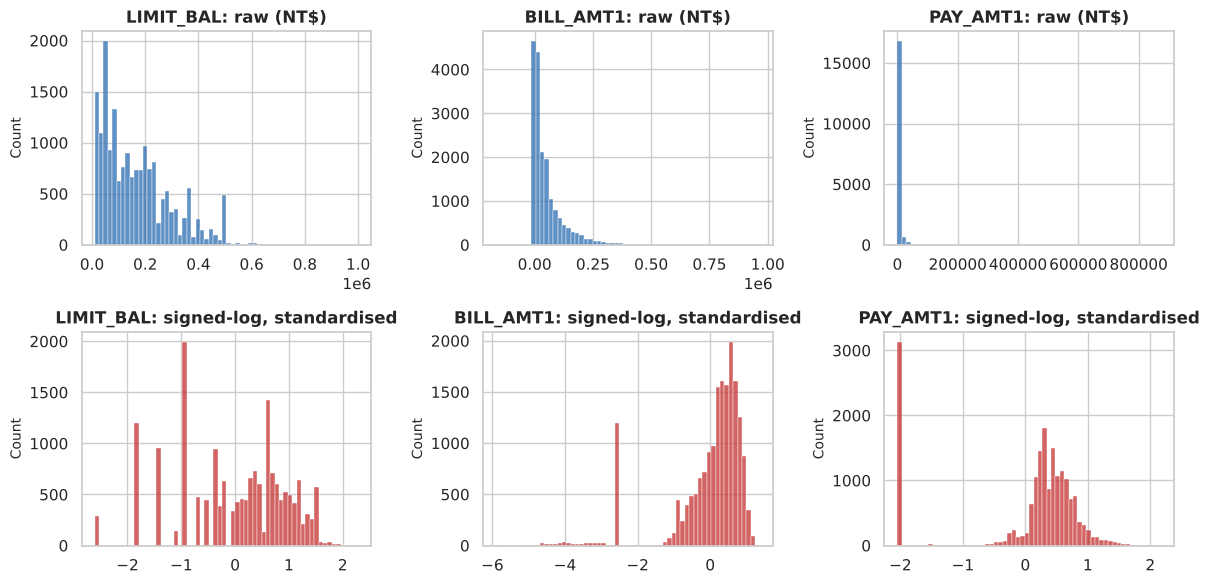

In [5]:
cols = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]
viz.plot_transform_effect(X_tr, Z_tr, cols)

Raw amounts are extremely right-skewed with a long tail of large balances. The signed-log transform compresses the tail while preserving negative balances; the rows are kept, not deleted.

## 4. Multicollinearity (VIF on training features)

max VIF base: {'PAY_5': 6.9, 'PAY_4': 6.6, 'BILL_AMT3': 6.0}
max VIF engineered: {'util_avg': 9.3, 'util_sep': 8.4, 'PAY_5': 7.1, 'PAY_4': 6.8}


'results/figures/11_vif.png'

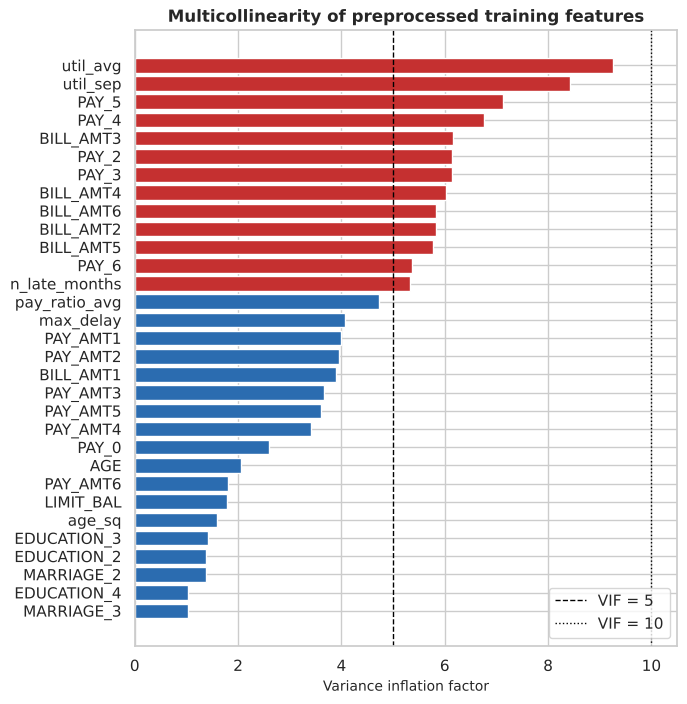

In [6]:
def vif_table(Z):
    A = Z.assign(const=1.0).values
    return pd.Series([variance_inflation_factor(A, i) for i in range(Z.shape[1])], index=Z.columns)

vif_eng = vif_table(Z_tr).sort_values(ascending=False)
Z_base = build_preprocessor("base").fit(X_tr).transform(X_tr)
vif_base = vif_table(Z_base).sort_values(ascending=False)
pd.concat([vif_base.rename("VIF_base"), vif_eng.rename("VIF_engineered")], axis=1).round(2).to_csv(f"{RESULTS}/vif_table.csv")
print("max VIF base:", vif_base.round(1).head(3).to_dict())
print("max VIF engineered:", vif_eng.round(1).head(4).to_dict())
viz.plot_vif(vif_eng)

**Interpretation.** In raw correlation the six bill-amount columns were at least 0.80 correlated. After the signed-log transform and with the full set, the base-feature VIFs are moderate (largest ≈ 6.9 for `PAY_5`, bills 5.6–6.0), below the conventional 10 threshold. The engineered utilisation features are the most collinear (≈ 8.4 and 9.3), because they are built from the bill columns and the limit. Nothing is dropped on VIF alone; L1/L2 regularisation in Stage 5 handles the correlated block, and coefficient stability will be examined in the credit-risk analysis. Feature selection proper is left to L1.

## 5. Choosing a feature set
Four candidates are compared with a fixed L2 logistic regression (C = 1): base vs engineered features, each with and without SEX. Evidence is 5-fold stratified CV on the **training** set (preprocessing refitted inside each fold) and validation-set performance. This is a feature-set decision, not hyperparameter tuning.

,cv_roc_auc_mean,cv_roc_auc_std,val_roc_auc,val_pr_auc
base,0.7480,0.0100,0.7306,0.4864
base + SEX,0.7484,0.0103,0.7309,0.4864
engineered,0.7641,0.0076,0.7478,0.4937
engineered + SEX,0.7648,0.0078,0.7482,0.4938


'results/figures/12_feature_set_comparison.png'

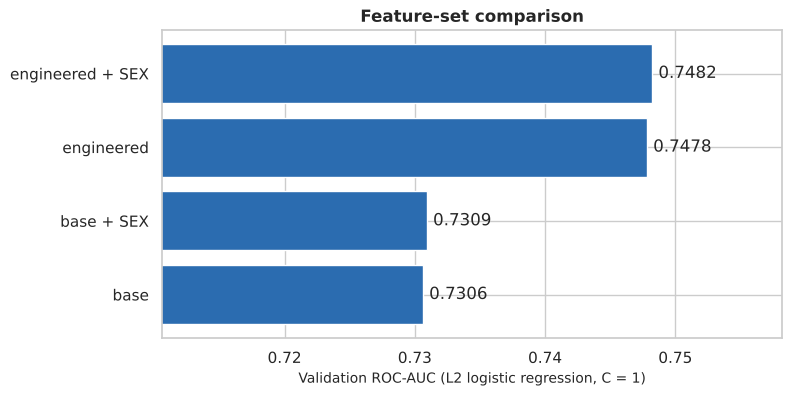

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = {}
for fs in ("base", "engineered"):
    for sex in (False, True):
        pipe = Pipeline([("prep", build_preprocessor(fs, include_sex=sex)),
                         ("clf", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))])
        cvs = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="roc_auc")
        pipe.fit(X_tr, y_tr); p = pipe.predict_proba(X_va)[:, 1]
        rows[f"{fs}{' + SEX' if sex else ''}"] = {"cv_roc_auc_mean": cvs.mean(), "cv_roc_auc_std": cvs.std(),
                                                  "val_roc_auc": roc_auc_score(y_va, p),
                                                  "val_pr_auc": average_precision_score(y_va, p)}
tab = pd.DataFrame(rows).T.round(4)
tab.to_csv(f"{RESULTS}/feature_set_comparison.csv")
display(tab)
viz.plot_feature_set_comparison(tab)

**Decision.**
- **Engineered features help:** validation ROC-AUC rises from 0.7306 to 0.7478 and CV ROC-AUC from 0.748 to 0.764, a gain of about 0.016 that is larger than the fold-to-fold standard deviation (≈ 0.008–0.010) and consistent across CV and validation, although I have not run a formal paired test. Validation PR-AUC rises from 0.486 to 0.494.
- **SEX adds nothing:** changes of +0.0003 to +0.0004 ROC-AUC are negligible, so excluding SEX costs no predictive performance and avoids a fair-lending issue. SEX stays out of the main model.
- **Main feature set: engineered, without SEX** (`build_preprocessor("engineered")`).

These numbers use a placeholder regularisation strength; they are for choosing features only and are not the final model results. The test set has not been used.